# segmentação de clientes com clustering (IA não supervisionada)

**mini projeto - IA / ML: clustering**

**dataset escolhido:** [Customer Personality Analysis (Kaggle)](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis)

## integrantes
- Guilherme Schnekenberg Teixeira (RA00336189)
- Luís Augusto Coelho de Souza (RA00331675)

## objetivo
agrupar os clientes de uma empresa de varejo em segmentos com perfis parecidos (renda, gastos, família, canais de compra), sem usar rótulos. Com isso a empresa pode direcionar produtos e campanhas para cada grupo, em vez de tratar todos os clientes da mesma forma.

## roteiro
1. carregamento e visão geral dos dados
2. dados faltantes (**missingno**)
3. limpeza e *feature engineering*
4. EDA - distribuições, outliers, categóricas e correlações (**matplotlib / seaborn**)
5. pré-processamento (encoding + padronização) e redução de dimensionalidade (**PCA**)
6. escolha do número de clusters (cotovelo + silhouette)
7. experimentos com modelos: **K-Means, Agglomerative, Gaussian Mixture, Affinity Propagation, DBSCAN**
8. perfil dos clusters e personas
9. conclusões

## **1. imports e carregamento**

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, AffinityPropagation, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
PALETA = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [48]:
# arquivo baixado do Kaggle (separado por TAB), armazenado no repositório github
url = "https://raw.github.com/schnekenberg/eda-customer-segmentation-clustering/main/marketing_campaign.csv"
df_raw = pd.read_csv("marketing_campaign.csv", sep="\t")
print("formato:", df_raw.shape)
df_raw.head()

formato: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [8]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [9]:
df_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.16,3246.66,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.81,11.98,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.25,25173.08,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.44,0.54,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.51,0.54,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.11,28.96,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.94,336.60,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.30,39.77,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.95,225.72,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.53,54.63,0.0,3.00,12.0,50.00,259.0


### dicionário resumido das colunas
| grupo | colunas |
|---|---|
| **Pessoa** | Year_Birth, Education, Marital_Status, Income, Kidhome, Teenhome, Dt_Customer, Recency, Complain |
| **Produtos** (gasto em 2 anos) | MntWines, MntFruits, MntMeatProducts, MntFishProducts, MntSweetProducts, MntGoldProds |
| **Promoção** | NumDealsPurchases, AcceptedCmp1..5, Response |
| **Canal** | NumWebPurchases, NumCatalogPurchases, NumStorePurchases, NumWebVisitsMonth |

In [10]:
# colunas constantes não carregam informação
print(df_raw[["Z_CostContact", "Z_Revenue"]].nunique())
print("\nIDs duplicados:", df_raw["ID"].duplicated().sum())

Z_CostContact    1
Z_Revenue        1
dtype: int64

IDs duplicados: 0


## **2. verificação de dados faltantes com missingno**

Income    24
dtype: int64


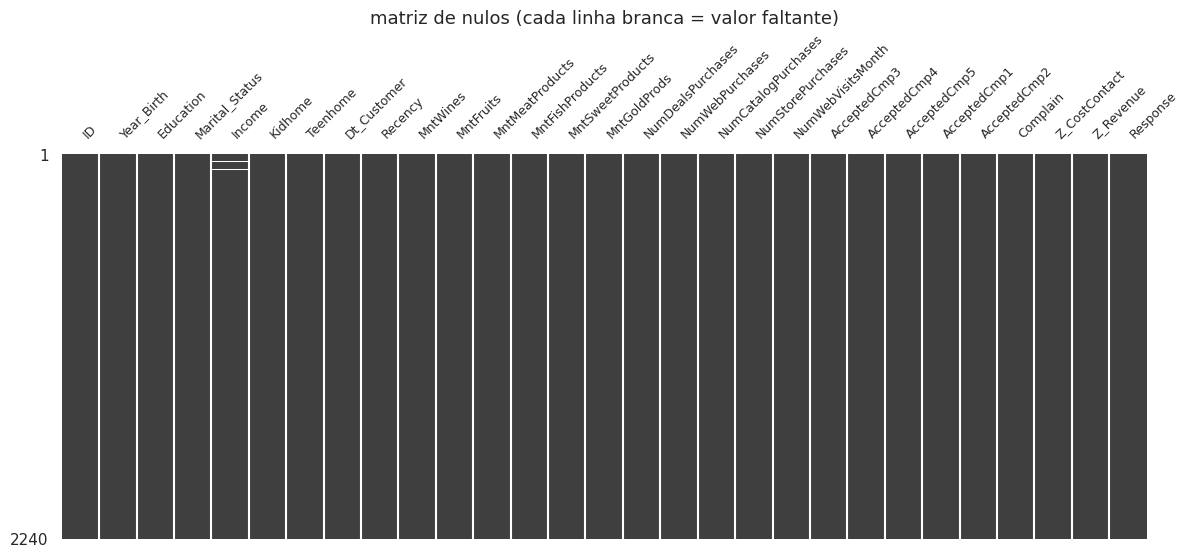

In [11]:
print(df_raw.isna().sum()[df_raw.isna().sum() > 0])
msno.matrix(df_raw, figsize=(14, 5), fontsize=9, sparkline=False)
plt.title("matriz de nulos (cada linha branca = valor faltante)", fontsize=13)
plt.show()

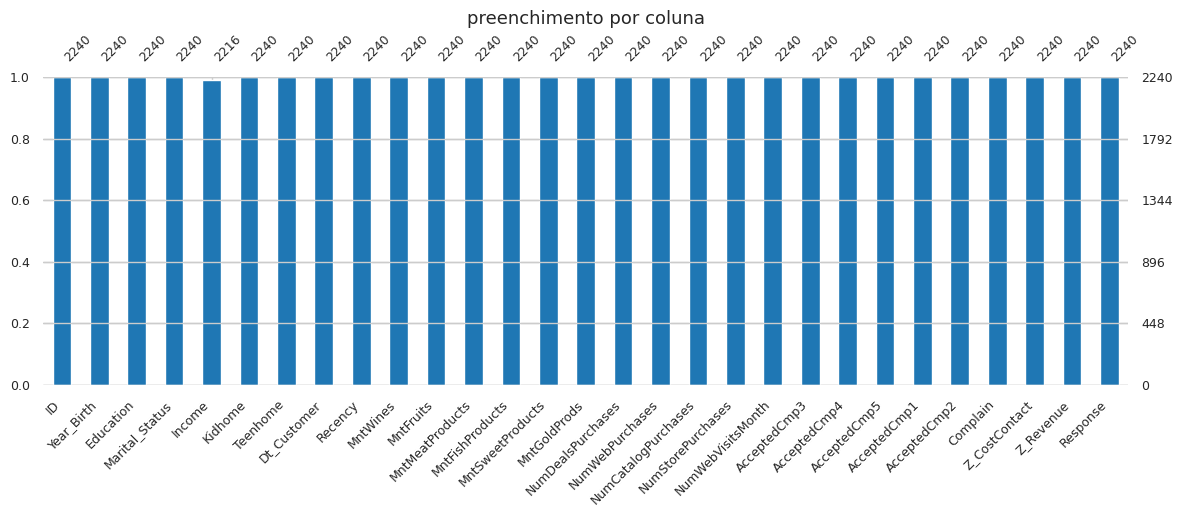

In [12]:
msno.bar(df_raw, figsize=(14, 4), fontsize=9, color="#1f77b4")
plt.title("preenchimento por coluna", fontsize=13)
plt.show()

In [49]:
# o msno.heatmap mostra se a ausência de uma coluna se relaciona com a ausência de outra.
# aqui ele não se aplica: só 'Income' tem nulos, então não há par de colunas para comparar.
# em vez disso, conferimos se as linhas sem renda têm um perfil diferente das demais.
falta = df_raw["Income"].isna()
print(f"nulos em Income: {falta.sum()} ({falta.mean():.1%} das linhas)")
df_raw.groupby(falta)[["Year_Birth", "MntWines", "MntMeatProducts", "NumStorePurchases"]].mean().round(1)

nulos em Income: 24 (1.1% das linhas)


,Year_Birth,MntWines,MntMeatProducts,NumStorePurchases
Income,,,,
False,1968.8,305.1,167.0,5.8
True,1967.5,197.2,162.7,4.8


**leitura:** só 'Income' tem valores faltantes (24 linhas, ~1%), espalhados sem padrão pelo dataset e sem relação clara com idade ou gastos. Por ser tão pouco, removemos essas linhas em vez de imputar, pois perder 1% dos dados não muda a análise e evita inventar renda.

## **3. limpeza e feature engineering**

In [14]:
df = df_raw.dropna(subset=["Income"]).copy()

# data de cadastro -> tempo como cliente (em dias), relativo ao cadastro mais recente
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="%d-%m-%Y")
print("cadastros entre", df["Dt_Customer"].min().date(), "e", df["Dt_Customer"].max().date())
df["Customer_For"] = (df["Dt_Customer"].max() - df["Dt_Customer"]).dt.days

# idade de referência no fim do período (2014)
df["Age"] = 2014 - df["Year_Birth"]

# gasto total e número total de compras
mnt = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
df["Spent"] = df[mnt].sum(axis=1)
df["NumPurchases"] = df[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)

# família
df["Living_With"] = df["Marital_Status"].replace({
    "Married": "Partner", "Together": "Partner",
    "Single": "Alone", "Divorced": "Alone", "Widow": "Alone",
    "Absurd": "Alone", "YOLO": "Alone", "Alone": "Alone"})
df["Children"] = df["Kidhome"] + df["Teenhome"]
df["Family_Size"] = df["Living_With"].map({"Alone": 1, "Partner": 2}) + df["Children"]
df["Is_Parent"] = (df["Children"] > 0).astype(int)

# escolaridade simplificada
df["Education"] = df["Education"].replace({
    "Basic": "Undergraduate", "2n Cycle": "Undergraduate",
    "Graduation": "Graduate", "Master": "Postgraduate", "PhD": "Postgraduate"})

# total de campanhas aceitas
cmp = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response"]
df["Total_Promos"] = df[cmp].sum(axis=1)

# renomeia gastos para leitura mais fácil
df = df.rename(columns={"MntWines": "Wines", "MntFruits": "Fruits", "MntMeatProducts": "Meat",
                        "MntFishProducts": "Fish", "MntSweetProducts": "Sweets", "MntGoldProds": "Gold"})

df = df.drop(columns=["ID", "Year_Birth", "Marital_Status", "Dt_Customer", "Z_CostContact", "Z_Revenue"])
print("formato após limpeza:", df.shape)
df.head()

cadastros entre 2012-07-30 e 2014-06-29
formato após limpeza: (2216, 32)


,Education,Income,Kidhome,Teenhome,Recency,Wines,Fruits,Meat,Fish,Sweets,...,Response,Customer_For,Age,Spent,NumPurchases,Living_With,Children,Family_Size,Is_Parent,Total_Promos
0,Graduate,58138.0,0,0,58,635,88,546,172,88,...,1,663,57,1617,22,Alone,0,1,0,1
1,Graduate,46344.0,1,1,38,11,1,6,2,1,...,0,113,60,27,4,Alone,2,3,1,0
2,Graduate,71613.0,0,0,26,426,49,127,111,21,...,0,312,49,776,20,Partner,0,2,0,0
3,Graduate,26646.0,1,0,26,11,4,20,10,3,...,0,139,30,53,6,Partner,1,3,1,0
4,Postgraduate,58293.0,1,0,94,173,43,118,46,27,...,0,161,33,422,14,Partner,1,3,1,0


In [15]:
print(df_raw["Marital_Status"].value_counts().to_string())

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2


as categorias 'Absurd' e 'YOLO' foram agrupadas em 'Alone' (morando sozinho).

## **4. EDA - análise exploratória de dados**

### 4.1 distribuições das variáveis numéricas (histogramas)

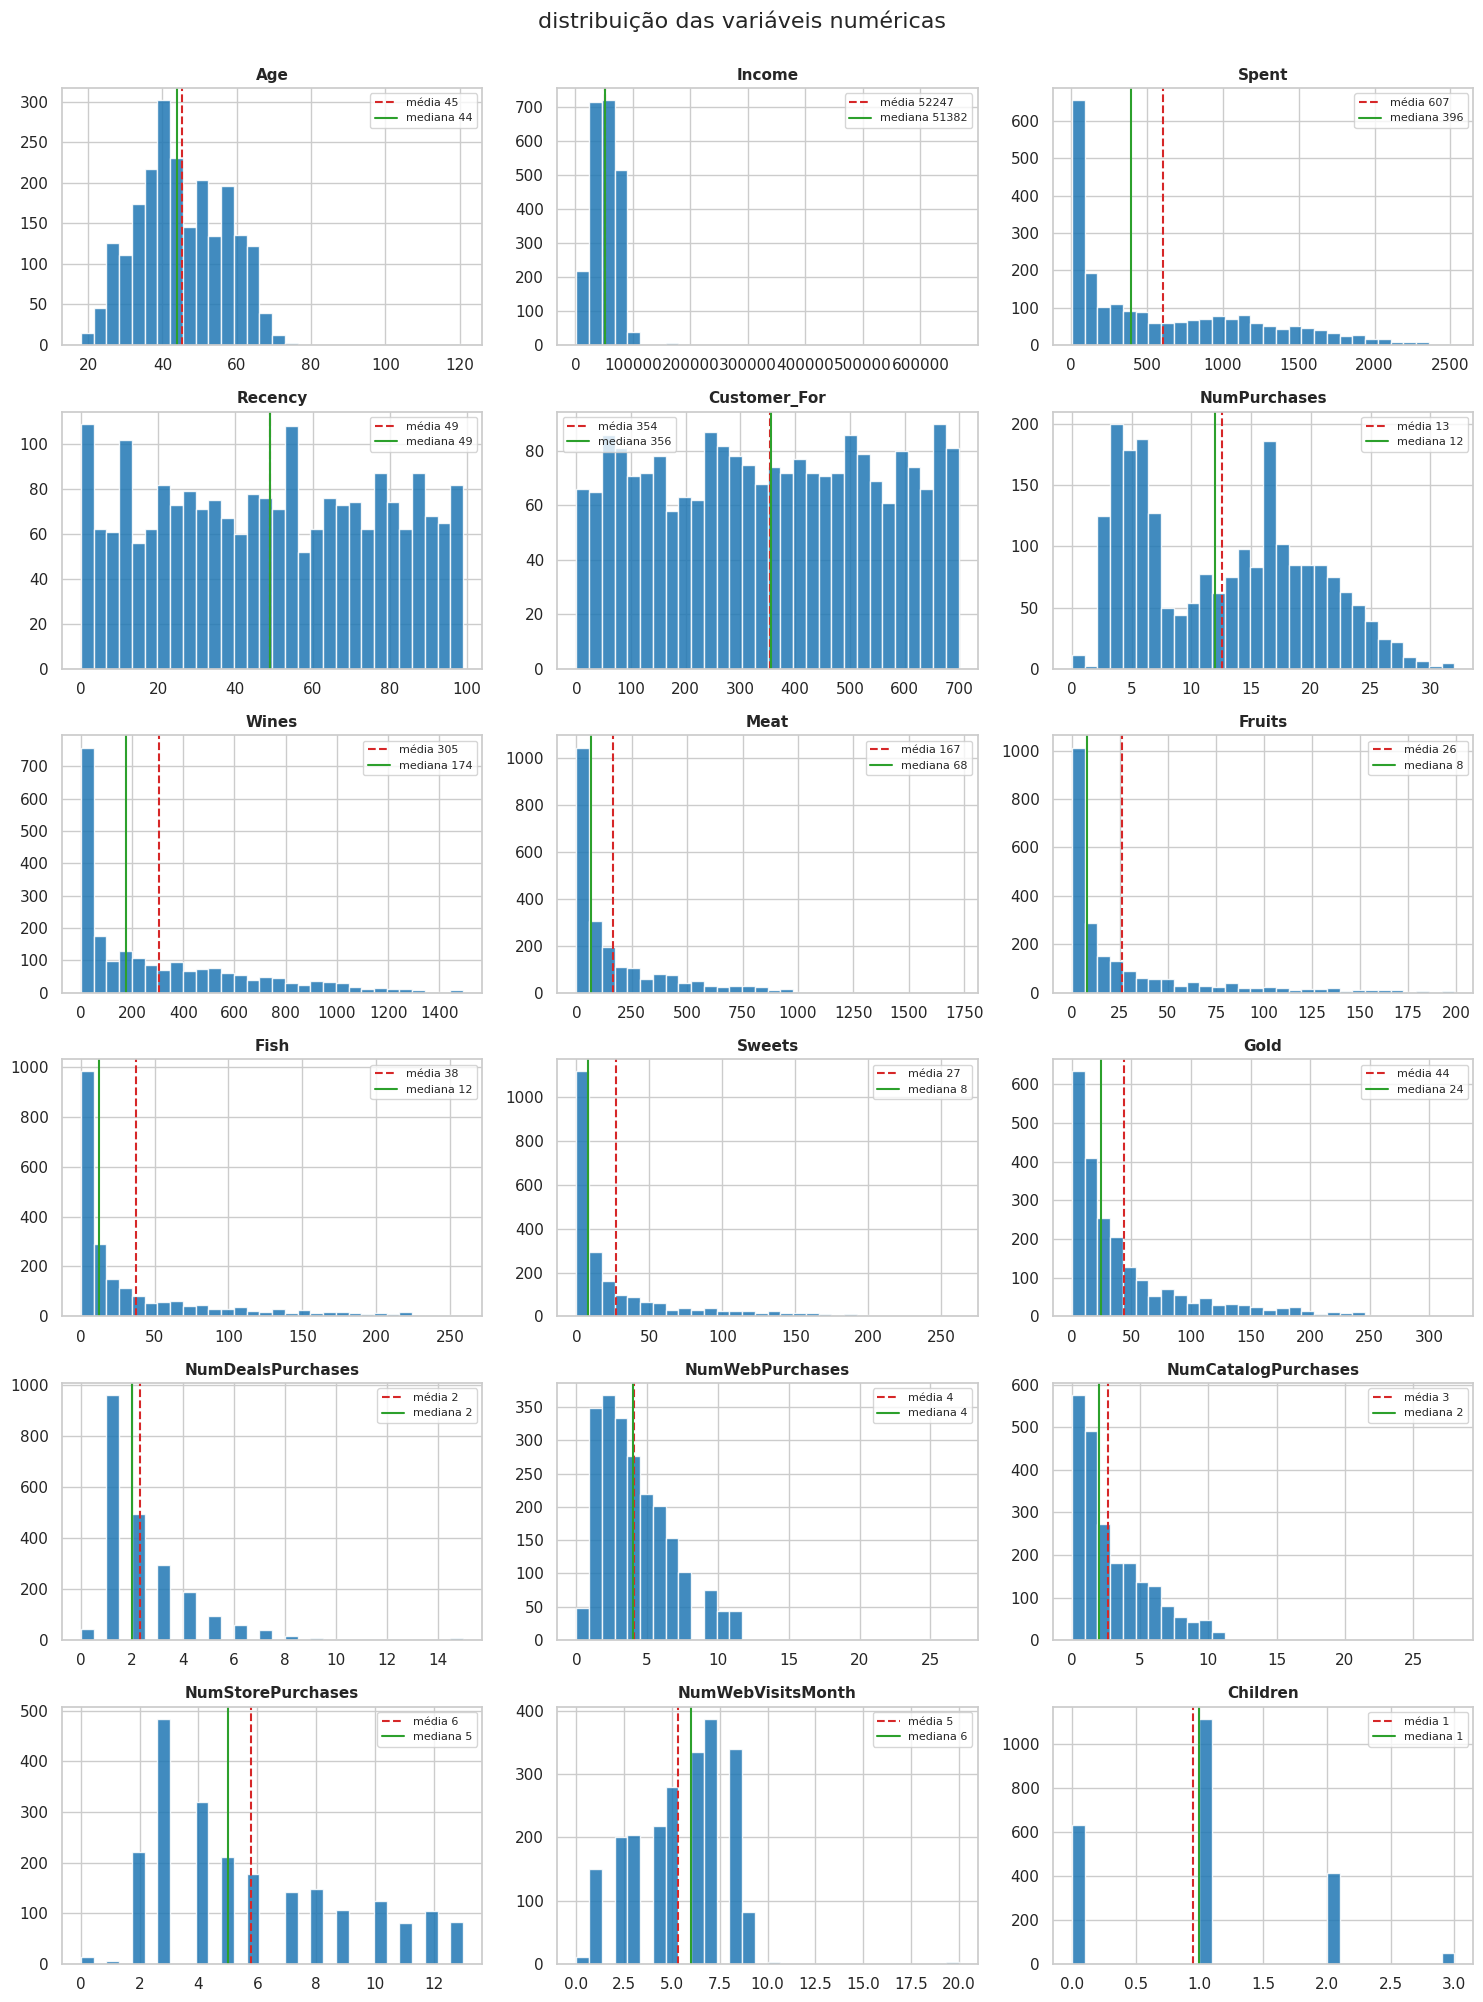

In [17]:
num_cols = ["Age", "Income", "Spent", "Recency", "Customer_For", "NumPurchases",
            "Wines", "Meat", "Fruits", "Fish", "Sweets", "Gold",
            "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases",
            "NumStorePurchases", "NumWebVisitsMonth", "Children"]

fig, axes = plt.subplots(6, 3, figsize=(15, 20))
for ax, col in zip(axes.flat, num_cols):
    ax.hist(df[col], bins=30, color="#1f77b4", edgecolor="white", alpha=0.85)
    ax.axvline(df[col].mean(), color="#d62728", ls="--", lw=1.5, label=f"média {df[col].mean():.0f}")
    ax.axvline(df[col].median(), color="#2ca02c", ls="-", lw=1.5, label=f"mediana {df[col].median():.0f}")
    ax.set_title(col, fontsize=11, weight="bold")
    ax.legend(fontsize=8)
plt.suptitle("distribuição das variáveis numéricas", fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

In [18]:
# assimetria: valores > 1 indicam cauda longa à direita
df[num_cols].skew().sort_values(ascending=False).round(2).to_frame("skew")

,skew
Income,6.76
NumDealsPurchases,2.42
Sweets,2.10
Fruits,2.10
Meat,2.03
Fish,1.92
NumCatalogPurchases,1.88
Gold,1.84
NumWebPurchases,1.20
Wines,1.17


**leitura:**
- Os gastos por produto (Wines, Meat, Fruits, Fish, Sweets, Gold) e o Spent têm cauda longa à direita: a maioria gasta pouco e poucos clientes gastam muito. É exatamente esse contraste que o clustering deve capturar.
- Recency e Customer_For são praticamente uniformes e não devem diferenciar muito os grupos.
- Age e Income parecem quase normais, mas com alguns pontos isolados muito distantes (próximo passo).

### **4.2 outliers (boxplots)**

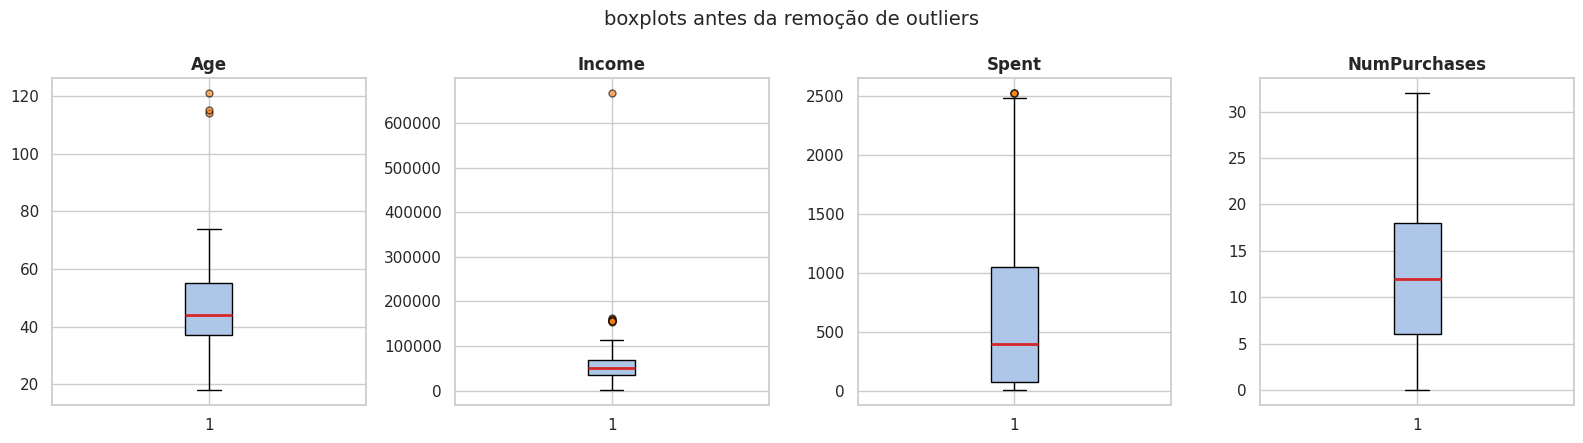

idades > 90: [114, 121, 115]
rendas > 600k: [666666.0]


In [19]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for ax, col in zip(axes, ["Age", "Income", "Spent", "NumPurchases"]):
    ax.boxplot(df[col], vert=True, patch_artist=True,
               boxprops=dict(facecolor="#aec7e8"), medianprops=dict(color="#d62728", lw=2),
               flierprops=dict(marker="o", markerfacecolor="#ff7f0e", markersize=5, alpha=0.6))
    ax.set_title(col, weight="bold")
plt.suptitle("boxplots antes da remoção de outliers", fontsize=14)
plt.tight_layout()
plt.show()

print("idades > 90:", df.loc[df["Age"] > 90, "Age"].tolist())
print("rendas > 600k:", df.loc[df["Income"] > 600_000, "Income"].tolist())

removidas 4 linhas. restam 2212 clientes.


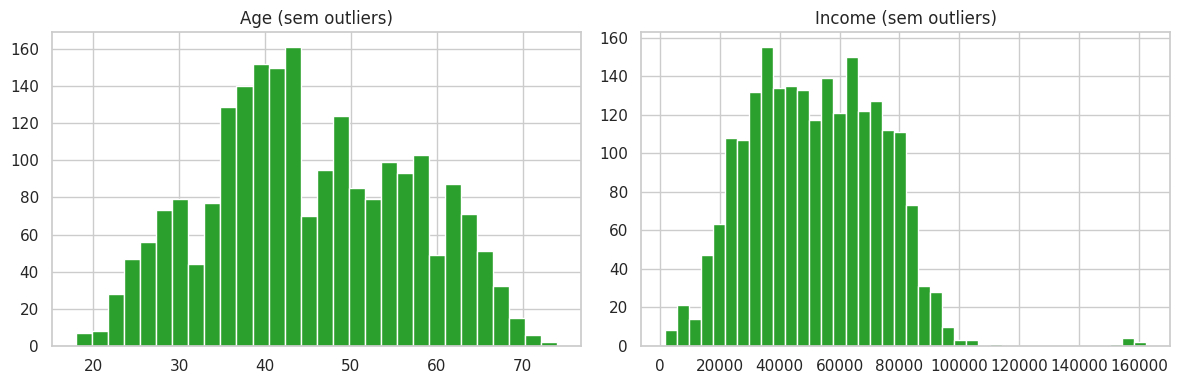

In [20]:
antes = len(df)
df = df[(df["Age"] < 90) & (df["Income"] < 600_000)].copy()
print(f"removidas {antes - len(df)} linhas. restam {len(df)} clientes.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["Age"], bins=30, color="#2ca02c", edgecolor="white"); axes[0].set_title("Age (sem outliers)")
axes[1].hist(df["Income"], bins=40, color="#2ca02c", edgecolor="white"); axes[1].set_title("Income (sem outliers)")
plt.tight_layout(); plt.show()

idades acima de 110 anos (nascidos em ~1900) e uma renda de 666 mil são erros de cadastro e distorceriam a padronização e as distâncias usadas pelos algoritmos de cluster.

### **4.3 Variáveis categóricas e binárias**

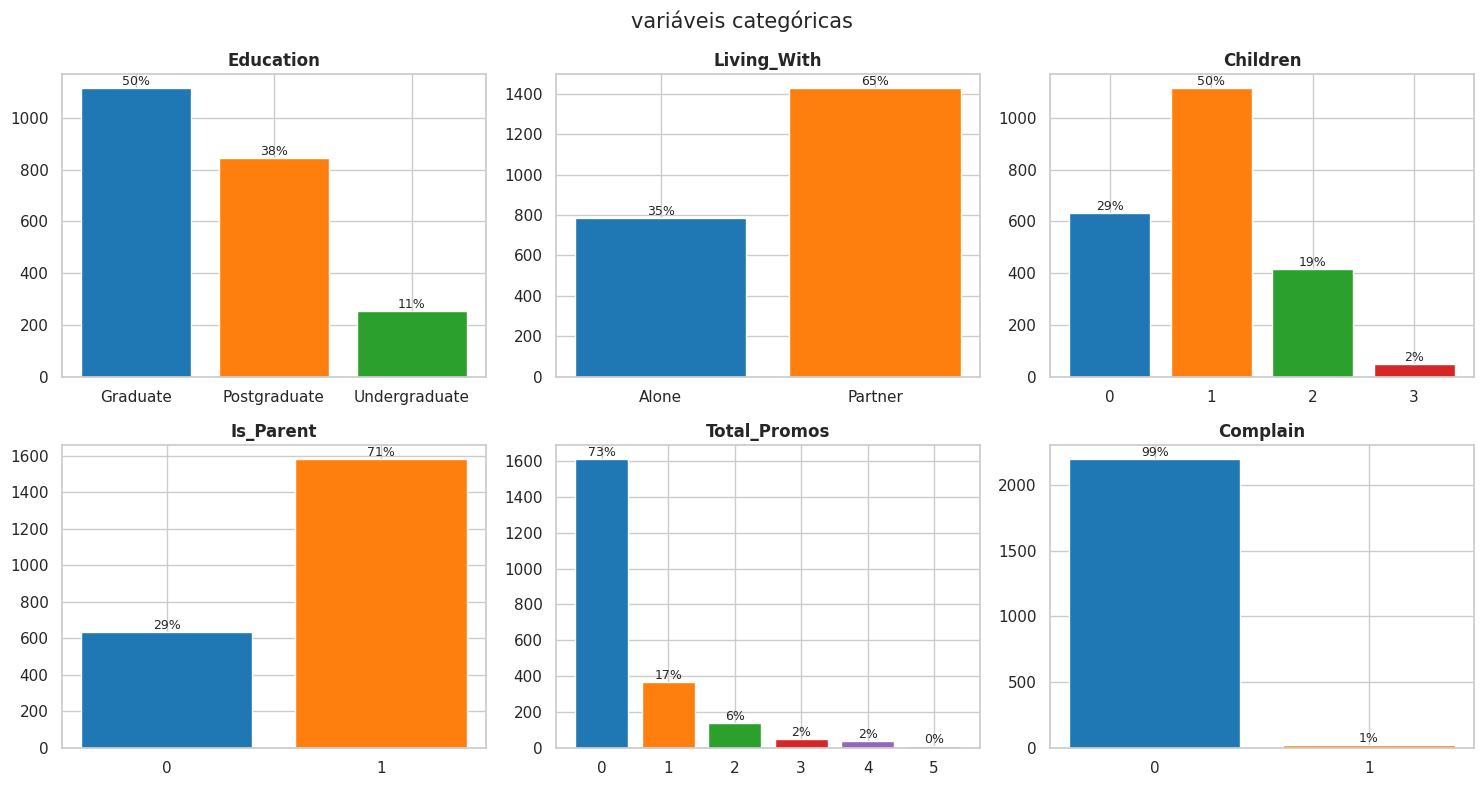

In [21]:
cats = ["Education", "Living_With", "Children", "Is_Parent", "Total_Promos", "Complain"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cats):
    vc = df[col].value_counts().sort_index()
    bars = ax.bar(vc.index.astype(str), vc.values, color=PALETA[:len(vc)] if len(vc) <= 6 else "#1f77b4")
    ax.bar_label(bars, labels=[f"{v/len(df):.0%}" for v in vc.values], fontsize=9)
    ax.set_title(col, weight="bold")
plt.suptitle("variáveis categóricas", fontsize=15)
plt.tight_layout()
plt.show()

**leitura:** aprox. 72% dos clientes têm filhos, aprox. 64% moram com parceiro(a) e metade tem graduação. Complain é quase sempre 0 (aprox. 1% de reclamações) e quase 80% nunca aceitou nenhuma campanha.

### **4.4 para onde vai o dinheiro: produtos e canais**

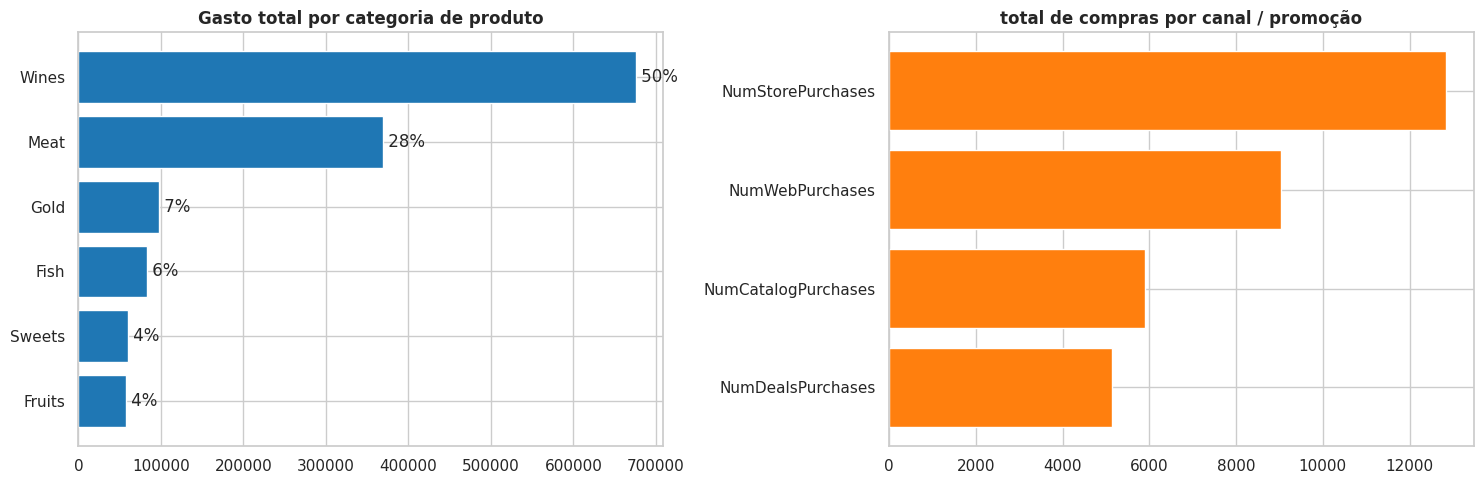

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

prod = df[["Wines", "Meat", "Gold", "Fish", "Sweets", "Fruits"]].sum().sort_values()
axes[0].barh(prod.index, prod.values, color="#1f77b4")
for i, v in enumerate(prod.values):
    axes[0].text(v, i, f" {v/prod.sum():.0%}", va="center")
axes[0].set_title("Gasto total por categoria de produto", weight="bold")

canais = df[["NumStorePurchases", "NumWebPurchases", "NumCatalogPurchases", "NumDealsPurchases"]].sum().sort_values()
axes[1].barh(canais.index, canais.values, color="#ff7f0e")
axes[1].set_title("total de compras por canal / promoção", weight="bold")
plt.tight_layout()
plt.show()

vinho e carne concentram cerca de 3/4 do faturamento; a loja física é o canal principal.

### **4.5 relações entre variáveis**

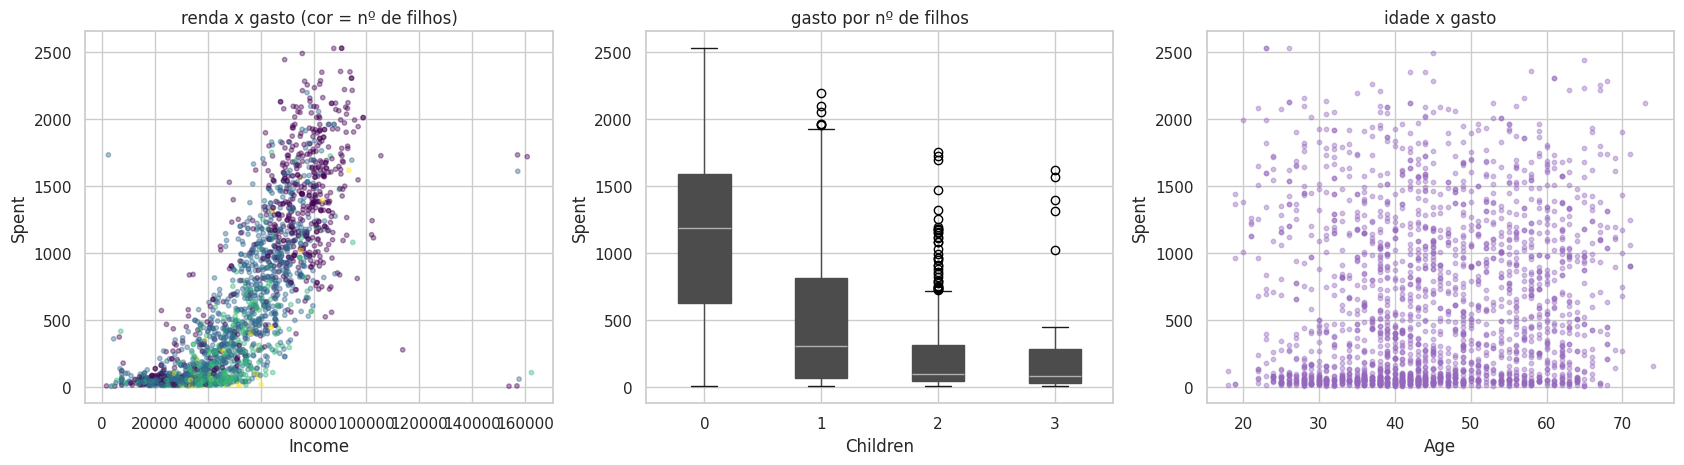

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].scatter(df["Income"], df["Spent"], s=10, alpha=0.4, c=df["Children"], cmap="viridis")
axes[0].set(xlabel="Income", ylabel="Spent", title="renda x gasto (cor = nº de filhos)")

df.boxplot(column="Spent", by="Children", ax=axes[1], patch_artist=True)
axes[1].set(title="gasto por nº de filhos", xlabel="Children", ylabel="Spent")

axes[2].scatter(df["Age"], df["Spent"], s=10, alpha=0.4, color="#9467bd")
axes[2].set(xlabel="Age", ylabel="Spent", title="idade x gasto")
plt.suptitle("")
plt.tight_layout()
plt.show()

**leitura:** renda e gasto têm relação forte e positiva; ter filhos reduz muito o gasto (clientes sem filhos gastam várias vezes mais). idade sozinha quase não explica o gasto.

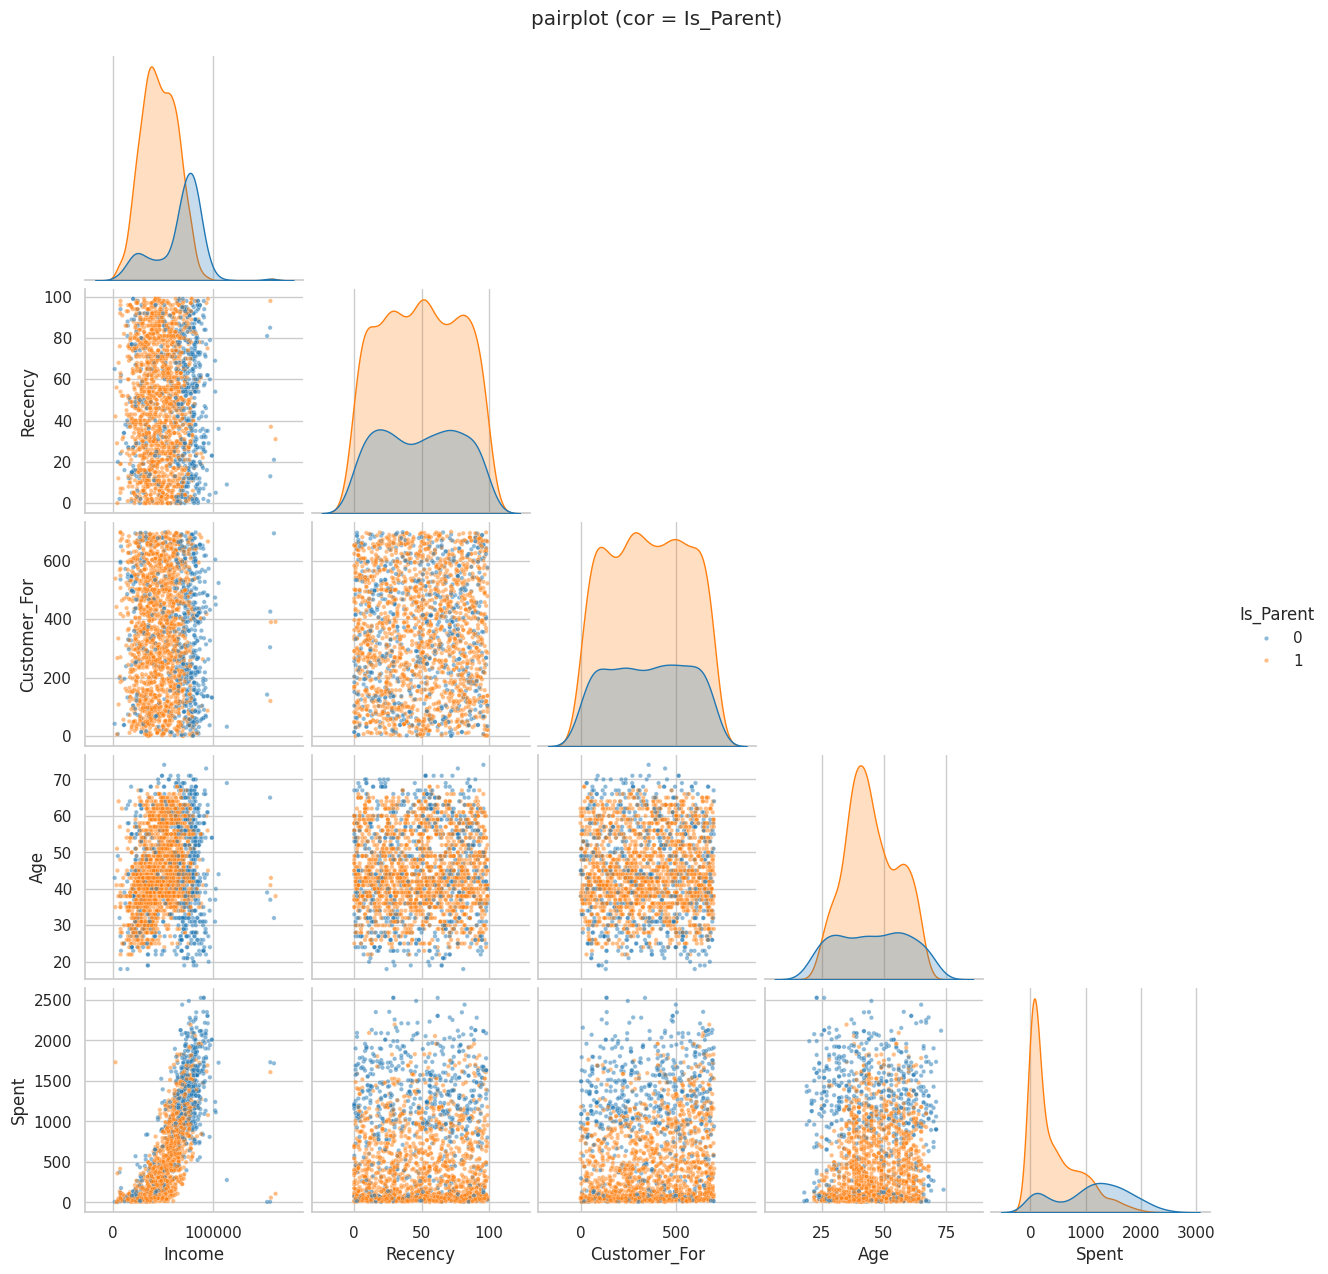

In [24]:
sns.pairplot(df[["Income", "Recency", "Customer_For", "Age", "Spent", "Is_Parent"]],
             hue="Is_Parent", palette=["#1f77b4", "#ff7f0e"], plot_kws=dict(s=10, alpha=0.5), corner=True)
plt.suptitle("pairplot (cor = Is_Parent)", y=1.02)
plt.show()

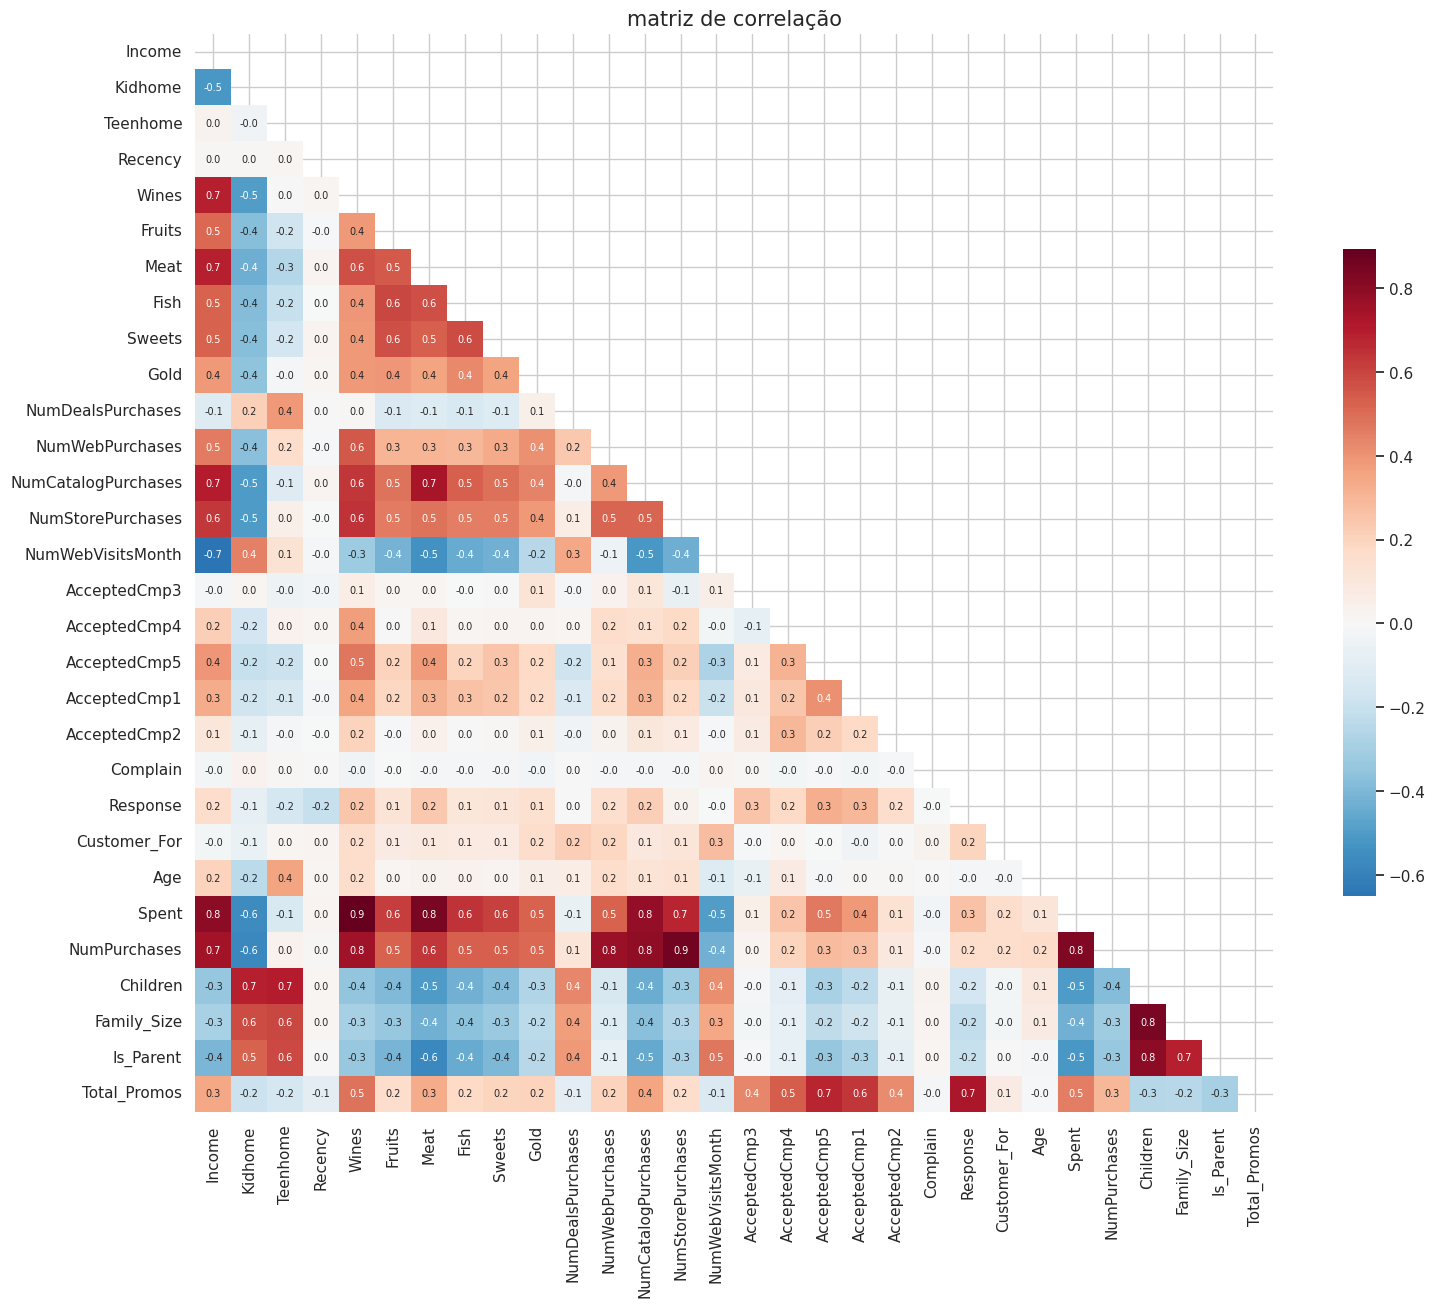

In [25]:
corr = df.select_dtypes("number").corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(18, 14))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7}, square=True, cbar_kws={"shrink": .6})
plt.title("matriz de correlação", fontsize=15)
plt.show()

In [26]:
# correlações mais fortes com o gasto total
corr["Spent"].drop("Spent").sort_values(key=abs, ascending=False).head(10).round(2)

,Spent
Wines,0.89
Meat,0.85
NumPurchases,0.82
Income,0.79
NumCatalogPurchases,0.78
NumStorePurchases,0.68
Fish,0.64
Fruits,0.61
Sweets,0.61
Kidhome,-0.56


muitas variáveis são fortemente correlacionadas entre si (gastos, número de compras, renda). isso justifica usar PCA antes do clustering para reduzir redundância.

## **5. pré-processamento e PCA**

In [27]:
# codifica as categóricas restantes
X = df.copy()
for col in ["Education", "Living_With"]:
    X[col] = LabelEncoder().fit_transform(X[col])

# as colunas de campanhas e reclamação ficam de fora do modelo; serão usadas depois para INTERPRETAR os clusters, não para formá-los
drop_cols = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5",
             "Response", "Complain", "Total_Promos"]
X = X.drop(columns=drop_cols)
print("features usadas no clustering:", X.shape[1])
print(list(X.columns))

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)
X_scaled.describe().T[["mean", "std"]].round(2).head()

features usadas no clustering: 24
['Education', 'Income', 'Kidhome', 'Teenhome', 'Recency', 'Wines', 'Fruits', 'Meat', 'Fish', 'Sweets', 'Gold', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'Customer_For', 'Age', 'Spent', 'NumPurchases', 'Living_With', 'Children', 'Family_Size', 'Is_Parent']


,mean,std
Education,0.0,1.0
Income,-0.0,1.0
Kidhome,0.0,1.0
Teenhome,0.0,1.0
Recency,0.0,1.0


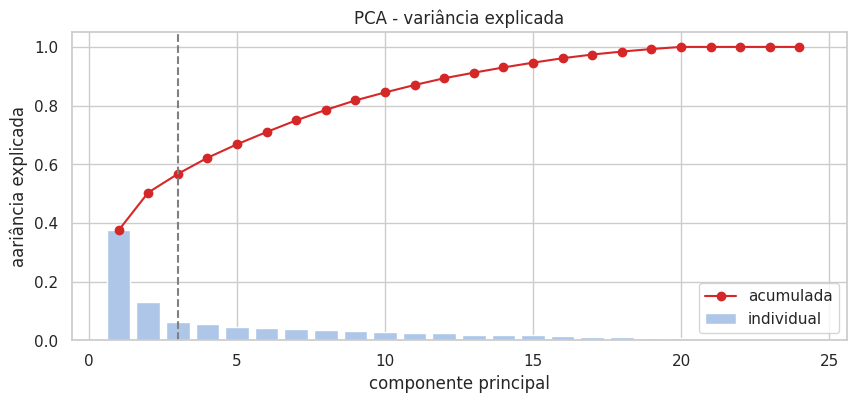

3 componentes explicam 56.7% da variância


In [28]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(1, len(var_acum) + 1), pca_full.explained_variance_ratio_, color="#aec7e8", label="individual")
ax.plot(range(1, len(var_acum) + 1), var_acum, "o-", color="#d62728", label="acumulada")
ax.axvline(3, ls="--", color="gray")
ax.set(xlabel="componente principal", ylabel="aariância explicada", title="PCA - variância explicada")
ax.legend(); plt.show()
print(f"3 componentes explicam {var_acum[2]:.1%} da variância")

In [29]:
pca = PCA(n_components=3, random_state=RANDOM_STATE)
X_pca = pd.DataFrame(pca.fit_transform(X_scaled), columns=["PC1", "PC2", "PC3"], index=X.index)

# o que cada componente representa (maiores pesos)
loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2", "PC3"])
for pc in loadings:
    top = loadings[pc].abs().sort_values(ascending=False).head(5).index
    print(pc, "->", ", ".join(f"{c} ({loadings.loc[c, pc]:+.2f})" for c in top))

PC1 -> Spent (+0.31), NumPurchases (+0.29), Meat (+0.27), Income (+0.27), NumCatalogPurchases (+0.27)
PC2 -> Teenhome (+0.44), NumDealsPurchases (+0.37), Family_Size (+0.35), Children (+0.35), Is_Parent (+0.31)
PC3 -> Customer_For (+0.55), NumWebVisitsMonth (+0.46), Living_With (-0.28), NumDealsPurchases (+0.28), Age (-0.27)


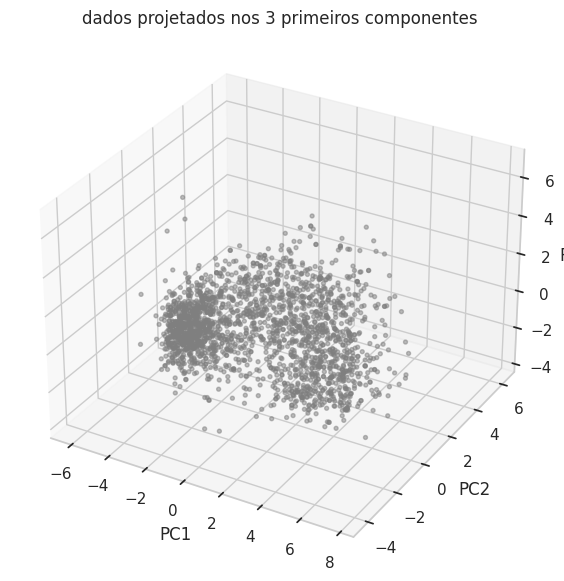

In [30]:
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X_pca.PC1, X_pca.PC2, X_pca.PC3, s=8, c="#7f7f7f", alpha=0.5)
ax.set(xlabel="PC1", ylabel="PC2", zlabel="PC3", title="dados projetados nos 3 primeiros componentes")
plt.show()

escolhemos 3 componentes para facilitar a visualização e reduzir ruído. A PC1 é basicamente "poder de consumo" (renda, gastos, nº de compras vs. filhos); a PC2 captura família/idade/tempo como cliente.

## **6. quantos clusters? Cotovelo + Silhouette**

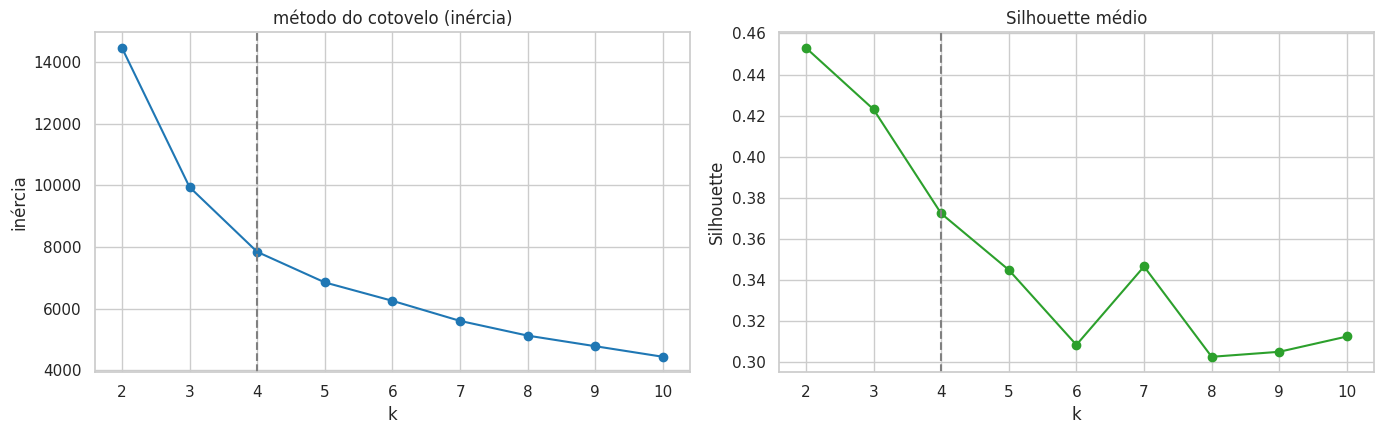

k,2,3,4,5,6,7,8,9,10
inercia,14475.000,9945.000,7841.000,6848.000,6250.000,5597.000,5119.000,4774.000,4430.000
silhouette,0.453,0.423,0.372,0.345,0.308,0.347,0.303,0.305,0.313


In [31]:
ks = range(2, 11)
inercia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
    inercia.append(km.inertia_)
    sil.append(silhouette_score(X_pca, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(ks, inercia, "o-", color="#1f77b4"); axes[0].set(title="método do cotovelo (inércia)", xlabel="k", ylabel="inércia")
axes[1].plot(ks, sil, "o-", color="#2ca02c"); axes[1].set(title="Silhouette médio", xlabel="k", ylabel="Silhouette")
for ax in axes: ax.axvline(4, ls="--", color="gray")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": ks, "inercia": np.round(inercia), "silhouette": np.round(sil, 3)}).set_index("k").T

**leitura:** o silhouette é máximo em k=2, mas dividir 2.200 clientes em só dois grupos ("gasta muito" vs. "gasta pouco") é pouco útil para marketing. O cotovelo da inércia fica entre 3 e 4, e k=4 ainda mantém silhouette razoável (aprox. 0,37). seguimos com k = 4, equilibrando qualidade estatística e utilidade de negócio.

## **7. experimentando modelos de clustering**

comparando algoritmos com lógicas diferentes:

| algoritmo | ideia | precisa de *k*? |
|---|---|---|
| **K-Means** | minimiza a distância de cada ponto ao centroide do seu grupo | sim |
| **Agglomerative (Ward)** | hierárquico: junta os pares de grupos mais próximos até sobrar *k* | sim |
| **Gaussian Mixture** | assume que cada grupo é uma "nuvem" gaussiana; atribuição probabilística | sim |
| **Affinity Propagation** | pontos "trocam mensagens" e elegem exemplares; descobre *k* sozinho | não |
| **DBSCAN** | grupos = regiões densas; pontos isolados viram ruído | não |

métricas internas (não temos rótulo verdadeiro):
- **Silhouette** (-1 a 1): quão bem cada ponto se encaixa no seu grupo vs. o vizinho
- **Calinski-Harabasz**: separação entre grupos / dispersão dentro
- **Davies-Bouldin**: similaridade média entre cada grupo e o mais parecido

In [32]:
K = 4
resultados, labels = [], {}

def avaliar(nome, lab):
    lab = np.asarray(lab)
    validos = lab != -1 # DBSCAN marca ruído como -1
    n_clusters = len(set(lab[validos]))
    linha = {"modelo": nome, "n_clusters": n_clusters, "ruido": int((~validos).sum())}
    if n_clusters > 1:
        Xv = X_pca[validos]
        linha.update(silhouette=silhouette_score(Xv, lab[validos]),
                     calinski_harabasz=calinski_harabasz_score(Xv, lab[validos]),
                     davies_bouldin=davies_bouldin_score(Xv, lab[validos]))
    resultados.append(linha); labels[nome] = lab

avaliar("K-Means", KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(X_pca))
avaliar("Agglomerative (Ward)", AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_pca))
avaliar("Gaussian Mixture", GaussianMixture(n_components=K, n_init=5, random_state=RANDOM_STATE).fit_predict(X_pca))

### Affinity Propagation - efeito do parâmetro 'preference'

In [33]:
# 'preference' controla quantos exemplares surgem: mais negativo -> menos clusters
for pref in [-50, -200, -500, -1000, -2000]:
    ap = AffinityPropagation(preference=pref, damping=0.9, max_iter=500, random_state=RANDOM_STATE).fit(X_pca)
    n = len(set(ap.labels_))
    s = silhouette_score(X_pca, ap.labels_) if n > 1 else np.nan
    print(f"preference={pref:>6}: {n:>3} clusters | silhouette={s:.3f}")

preference=   -50:  28 clusters | silhouette=0.257
preference=  -200:  11 clusters | silhouette=0.268
preference=  -500:   8 clusters | silhouette=0.308
preference= -1000:   5 clusters | silhouette=0.344
preference= -2000:   4 clusters | silhouette=0.359


In [34]:
AP_PREF = -1000
ap = AffinityPropagation(preference=AP_PREF, damping=0.9, max_iter=500, random_state=RANDOM_STATE).fit(X_pca)
avaliar(f"Affinity Propagation (pref={AP_PREF})", ap.labels_)

### DBSCAN - escolhendo 'eps' pelo gráfico de k-distâncias

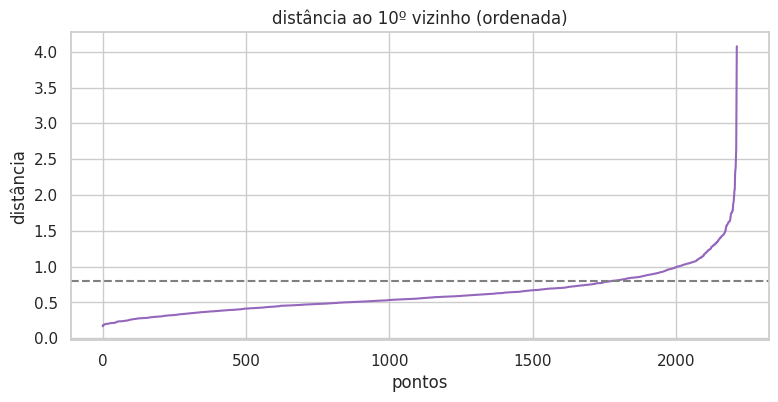

eps=0.6: 6 clusters, 547 pontos de ruído
eps=0.8: 3 clusters, 181 pontos de ruído
eps=0.9: 1 clusters, 98 pontos de ruído
eps=1.0: 1 clusters, 67 pontos de ruído
eps=1.2: 1 clusters, 27 pontos de ruído


In [35]:
nn = NearestNeighbors(n_neighbors=10).fit(X_pca)
dist = np.sort(nn.kneighbors(X_pca)[0][:, -1])
plt.figure(figsize=(9, 4))
plt.plot(dist, color="#9467bd"); plt.axhline(0.8, ls="--", color="gray")
plt.title("distância ao 10º vizinho (ordenada)"); plt.xlabel("pontos"); plt.ylabel("distância")
plt.show()

for eps in [0.6, 0.8, 0.9, 1.0, 1.2]:
    lab = DBSCAN(eps=eps, min_samples=10).fit_predict(X_pca)
    print(f"eps={eps}: {len(set(lab) - {-1})} clusters, {np.sum(lab == -1)} pontos de ruído")

In [36]:
avaliar("DBSCAN (eps=0.8)", DBSCAN(eps=0.8, min_samples=10).fit_predict(X_pca))

### **comparação dos modelos**

In [37]:
res = pd.DataFrame(resultados).set_index("modelo").round(3)
res

,n_clusters,ruido,silhouette,calinski_harabasz,davies_bouldin
modelo,,,,,
K-Means,4,0,0.372,2089.156,0.993
Agglomerative (Ward),4,0,0.355,1978.459,1.023
Gaussian Mixture,4,0,0.314,1604.915,0.981
Affinity Propagation (pref=-1000),5,0,0.344,1864.760,1.110
DBSCAN (eps=0.8),3,181,0.172,847.671,0.911


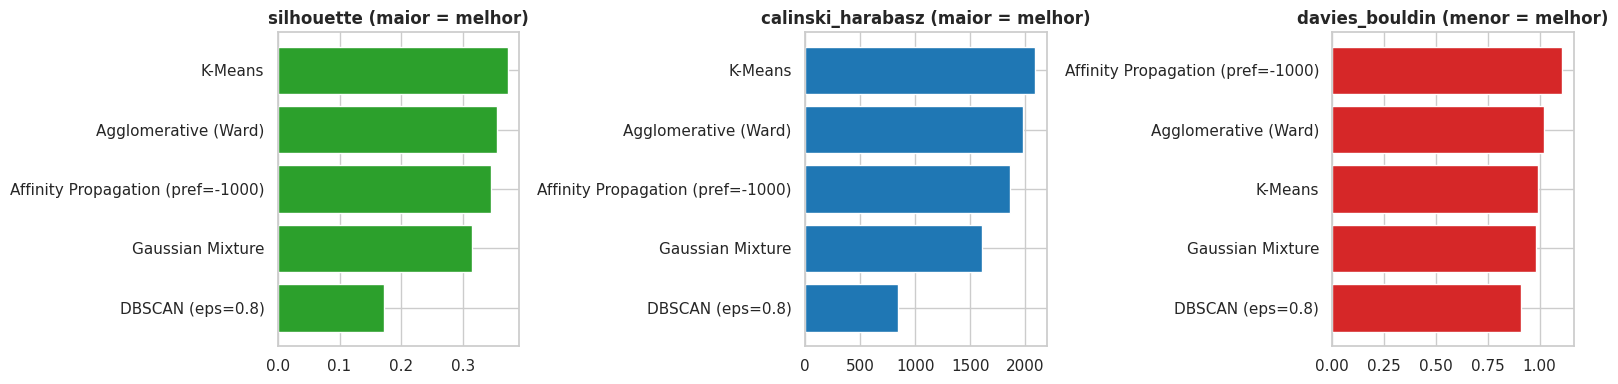

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (met, cor) in zip(axes, [("silhouette", "#2ca02c"), ("calinski_harabasz", "#1f77b4"), ("davies_bouldin", "#d62728")]):
    r = res[met].dropna().sort_values()
    ax.barh(r.index, r.values, color=cor)
    ax.set_title(met + (" (menor = melhor)" if met == "davies_bouldin" else " (maior = melhor)"), weight="bold")
plt.tight_layout(); plt.show()

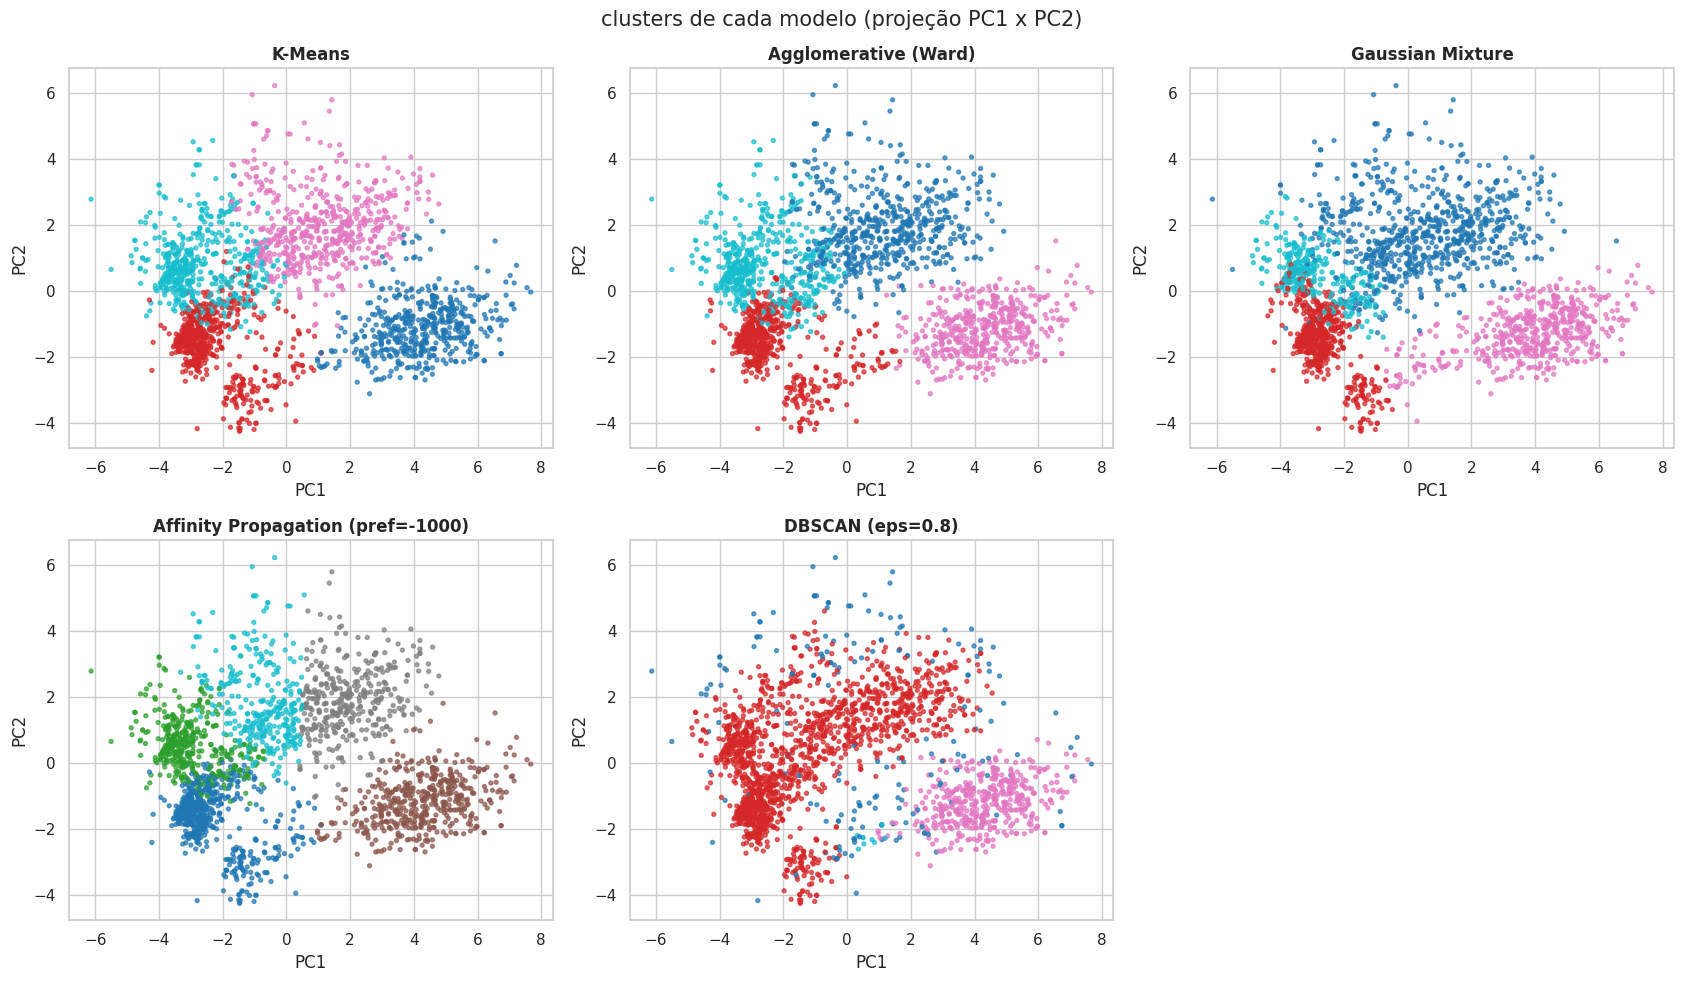

In [39]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10))
for ax, (nome, lab) in zip(axes.flat, labels.items()):
    ax.scatter(X_pca.PC1, X_pca.PC2, c=lab, s=8, cmap="tab10", alpha=0.7)
    ax.set_title(nome, weight="bold"); ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
axes.flat[-1].axis("off")
plt.suptitle("clusters de cada modelo (projeção PC1 x PC2)", fontsize=15)
plt.tight_layout(); plt.show()

**leitura da comparação:**
- **K-Means** teve o melhor silhouette e o melhor Calinski-Harabasz; seus grupos são compactos e bem separados na projeção.
- **Agglomerative (Ward)** chega a uma partição muito parecida (métricas um pouco piores) - é um bom sinal de que a estrutura de 4 grupos é real, e não um artefato de um único algoritmo.
- **Gaussian Mixture** teve Davies-Bouldin um pouco melhor que o K-Means, mas silhouette e Calinski-Harabasz piores: ele cria um grupo grande e "esticado" no centro, menos fácil de interpretar.
- **Affinity Propagation** escolhe o número de grupos sozinho, mas isso depende totalmente do parâmetro 'preference' (de 28 a 4 clusters no teste). Com '-1000' encontrou 5 grupos, quebrando em dois o segmento de menor renda. Também é bem mais lento (O(n²) em memória).
- **DBSCAN** não funciona bem aqui: os dados não formam "ilhas" de densidade separadas, e sim uma nuvem contínua. Com 'eps=0.8' achou 3 grupos, mas descartou 181 clientes como ruído e teve o pior silhouette (0,17); seu Davies-Bouldin baixo é enganoso, pois só considera os pontos não-ruído. Com 'eps >= 0.9' tudo vira um único cluster.

**Modelo final: K-Means com k=4** - melhores métricas gerais, resultado estável e fácil de explicar.

## **8. perfil dos clusters (modelo final)**

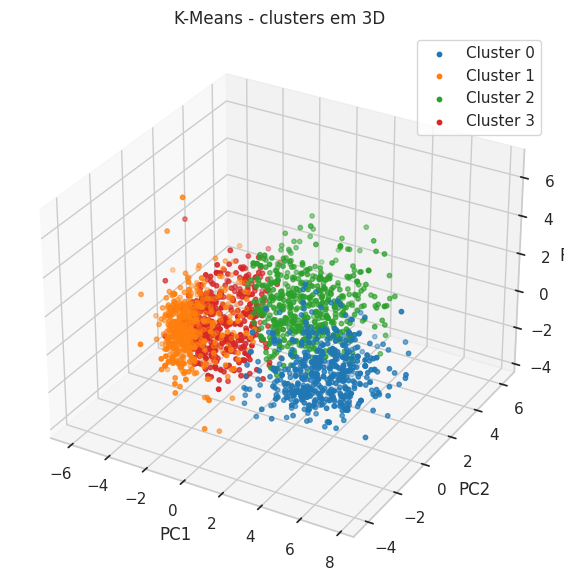

In [40]:
MODELO_FINAL = "K-Means"
df["Cluster"] = labels[MODELO_FINAL]

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")
for c in sorted(df["Cluster"].unique()):
    m = df["Cluster"] == c
    ax.scatter(X_pca.PC1[m], X_pca.PC2[m], X_pca.PC3[m], s=10, color=PALETA[c], label=f"Cluster {c}")
ax.set(xlabel="PC1", ylabel="PC2", zlabel="PC3", title=f"{MODELO_FINAL} - clusters em 3D"); ax.legend()
plt.show()

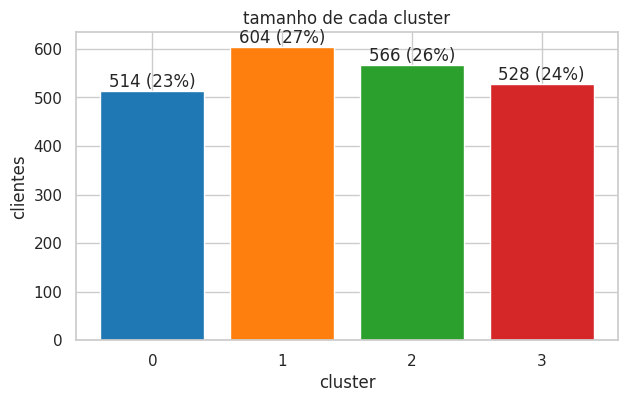

In [41]:
contagem = df["Cluster"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(contagem.index.astype(str), contagem.values, color=PALETA[:len(contagem)])
ax.bar_label(bars, labels=[f"{v} ({v/len(df):.0%})" for v in contagem.values])
ax.set(title="tamanho de cada cluster", xlabel="cluster", ylabel="clientes")
plt.show()

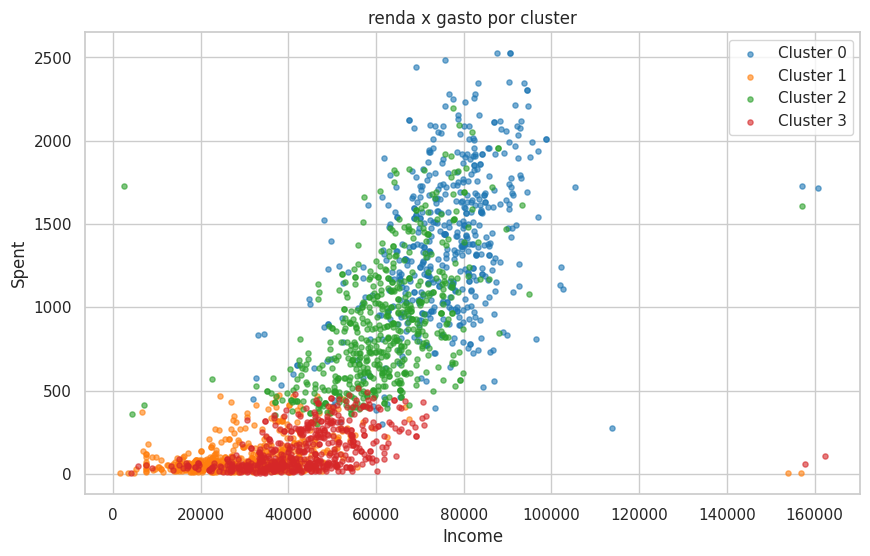

In [42]:
fig, ax = plt.subplots(figsize=(10, 6))
for c in sorted(df["Cluster"].unique()):
    m = df["Cluster"] == c
    ax.scatter(df.loc[m, "Income"], df.loc[m, "Spent"], s=14, alpha=0.6, color=PALETA[c], label=f"Cluster {c}")
ax.set(xlabel="Income", ylabel="Spent", title="renda x gasto por cluster"); ax.legend()
plt.show()

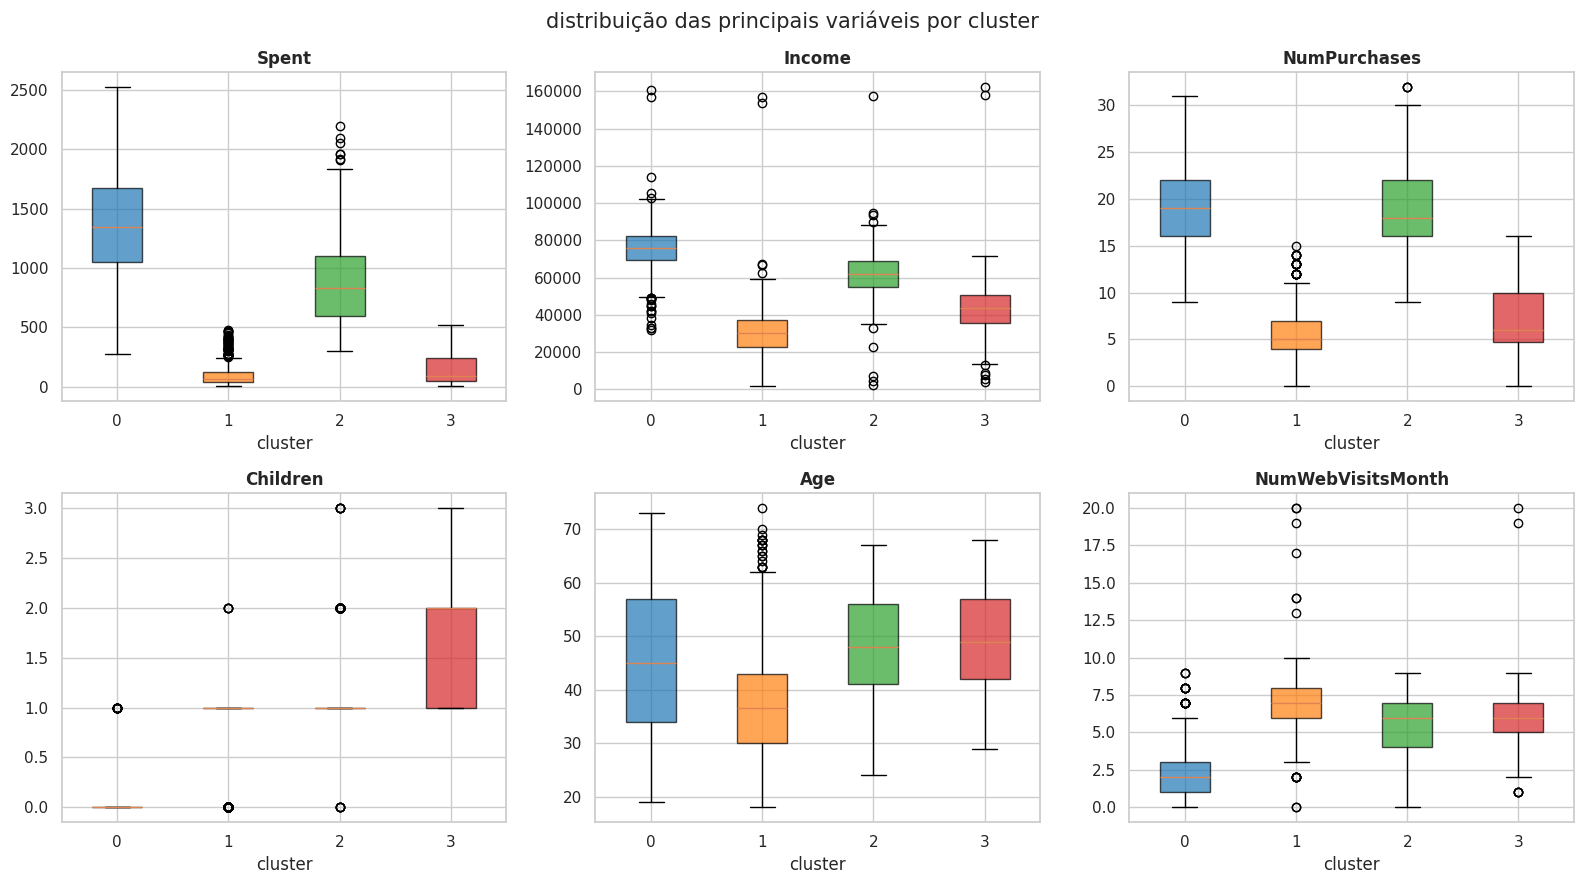

In [43]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, ["Spent", "Income", "NumPurchases", "Children", "Age", "NumWebVisitsMonth"]):
    grupos = [df.loc[df["Cluster"] == c, col] for c in sorted(df["Cluster"].unique())]
    bp = ax.boxplot(grupos, patch_artist=True, tick_labels=sorted(df["Cluster"].unique()))
    for patch, c in zip(bp["boxes"], PALETA): patch.set_facecolor(c); patch.set_alpha(0.7)
    ax.set_title(col, weight="bold"); ax.set_xlabel("cluster")
plt.suptitle("distribuição das principais variáveis por cluster", fontsize=15)
plt.tight_layout(); plt.show()

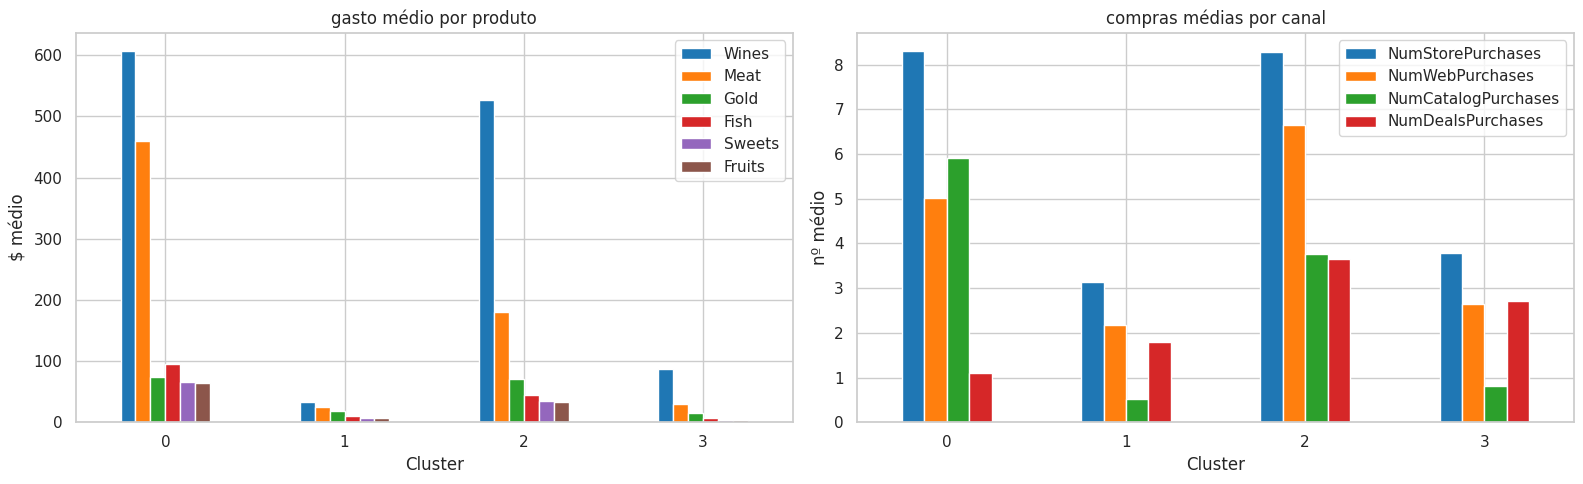

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

prod_cols = ["Wines", "Meat", "Gold", "Fish", "Sweets", "Fruits"]
df.groupby("Cluster")[prod_cols].mean().plot(kind="bar", ax=axes[0], color=PALETA)
axes[0].set(title="gasto médio por produto", ylabel="$ médio"); axes[0].tick_params(axis="x", rotation=0)

canal_cols = ["NumStorePurchases", "NumWebPurchases", "NumCatalogPurchases", "NumDealsPurchases"]
df.groupby("Cluster")[canal_cols].mean().plot(kind="bar", ax=axes[1], color=PALETA)
axes[1].set(title="compras médias por canal", ylabel="nº médio"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

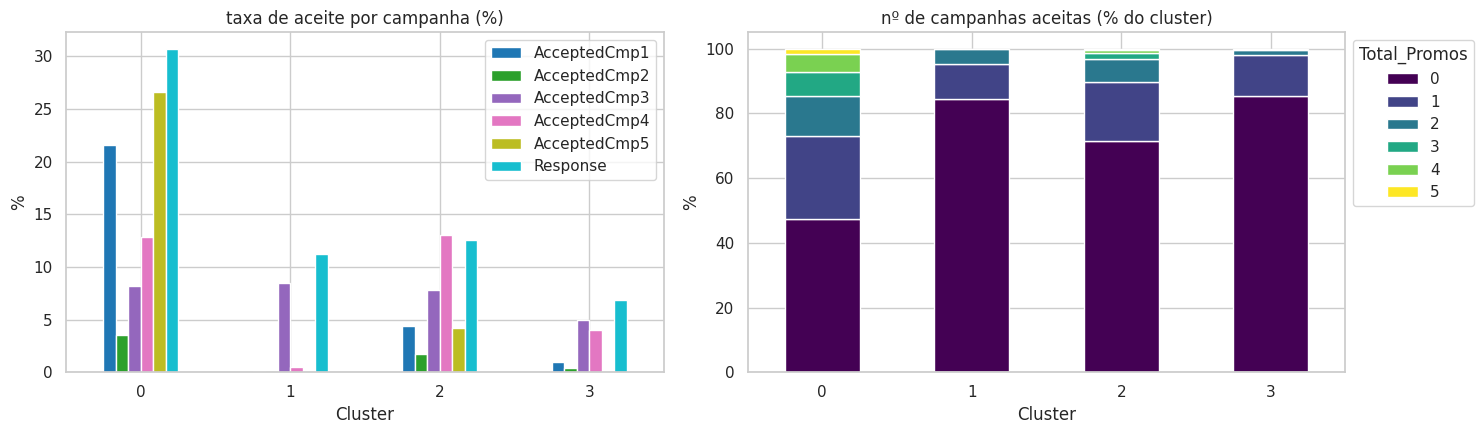

In [45]:
# campanhas não entraram no modelo: aqui usamos para validar se os grupos fazem sentido
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
taxa = df.groupby("Cluster")[["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response"]].mean() * 100
taxa.plot(kind="bar", ax=axes[0], colormap="tab10")
axes[0].set(title="taxa de aceite por campanha (%)", ylabel="%"); axes[0].tick_params(axis="x", rotation=0)

pd.crosstab(df["Cluster"], df["Total_Promos"], normalize="index").mul(100).plot(kind="bar", stacked=True, ax=axes[1], colormap="viridis")
axes[1].set(title="nº de campanhas aceitas (% do cluster)", ylabel="%"); axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Total_Promos", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

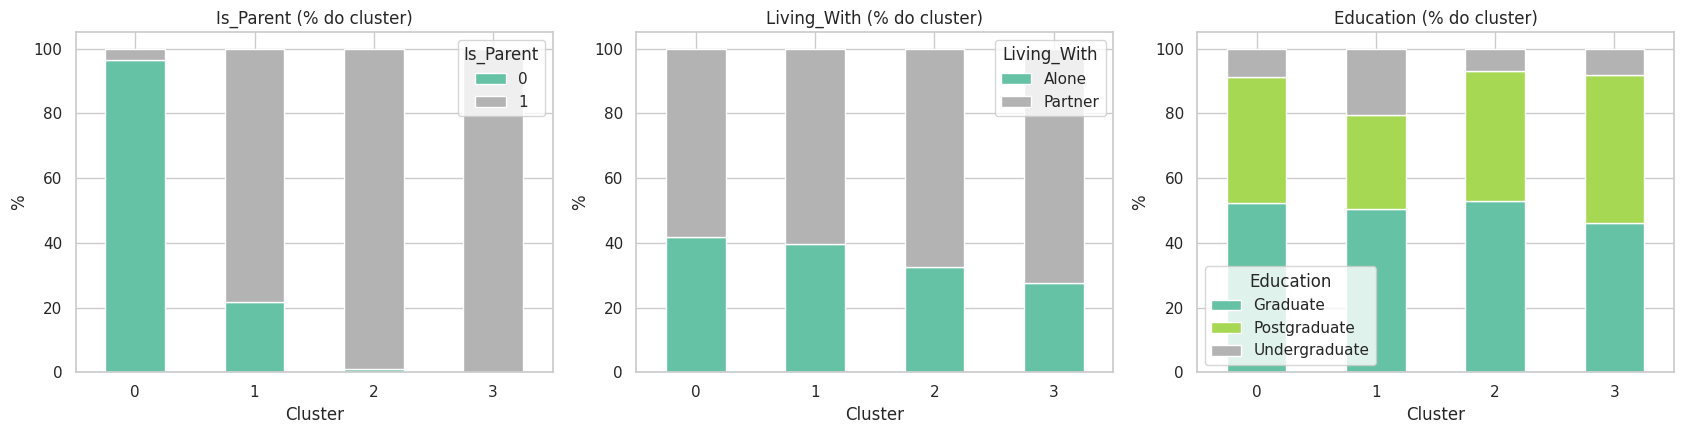

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["Is_Parent", "Living_With", "Education"]):
    pd.crosstab(df["Cluster"], df[col], normalize="index").mul(100).plot(kind="bar", stacked=True, ax=ax, colormap="Set2")
    ax.set(title=f"{col} (% do cluster)", ylabel="%"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

In [47]:
perfil = df.groupby("Cluster").agg(
    clientes=("Income", "size"), renda_media=("Income", "mean"), gasto_medio=("Spent", "mean"),
    compras=("NumPurchases", "mean"), compras_promo=("NumDealsPurchases", "mean"),
    visitas_web=("NumWebVisitsMonth", "mean"), idade=("Age", "mean"), filhos=("Children", "mean"),
    criancas=("Kidhome", "mean"), adolescentes=("Teenhome", "mean"),
    tam_familia=("Family_Size", "mean"), pct_pais=("Is_Parent", "mean"), campanhas_aceitas=("Total_Promos", "mean"))
perfil.round(2)

,clientes,renda_media,gasto_medio,compras,compras_promo,visitas_web,idade,filhos,criancas,adolescentes,tam_familia,pct_pais,campanhas_aceitas
Cluster,,,,,,,,,,,,,
0,514,75569.48,1366.59,19.22,1.10,2.69,45.81,0.04,0.00,0.03,1.62,0.04,1.04
1,604,30306.02,98.81,5.82,1.78,6.79,37.65,0.79,0.73,0.06,2.39,0.78,0.20
2,566,61661.76,889.58,18.69,3.66,5.51,48.31,1.15,0.21,0.94,2.83,0.99,0.44
3,528,43342.39,147.10,7.23,2.71,5.99,49.42,1.80,0.79,1.01,3.52,1.00,0.17


### personas

| cluster | % base | persona | perfil |
|---|---|---|---|
| **0** | \~23% | **premium sem filhos** | maior renda (\~75k) e maior gasto (\~1.370). quase ninguém tem filhos; família pequena. compra muito vinho e carne, em loja e catálogo, quase não usa promoção e visita pouco o site. é quem mais aceita campanhas (ex.: \~31% na última). |
| **2** | \~26% | **pais estabelecidos, caçadores de ofertas** | renda média-alta (\~62k), gasto alto (\~890), praticamente todos são pais (mais adolescentes que crianças), idade média \~48. usam todos os canais, principalmente web, e são os que mais compram em promoção. |
| **3** | \~24% | **famílias grandes, orçamento apertado** | renda média-baixa (\~43k), gasto baixo (\~150), maior família (\~3,5 pessoas; \~1,8 filhos), idade \~49. compram pouco, com peso relevante de promoções. raramente aceitam campanhas. |
| **1** | \~27% | **jovens de baixa renda** | menor renda (\~30k) e menor gasto (\~100), o grupo mais jovem (\~38 anos), geralmente com uma criança pequena. fazem mais visitas ao site por mês, mas pouca conversão em compra. |

## **9. conclusões**

- o pré-processamento teve impacto direto: removemos 24 linhas sem renda (identificadas com missingno), 4 outliers absurdos, e criamos variáveis mais informativas ('Spent', 'Children', 'Family_Size', 'Customer_For'...).
- a EDA mostrou que renda e presença de filhos são as variáveis que mais separam os clientes, e o PCA confirmou isso (PC1 = poder de consumo, PC2 = família).
- entre os cinco algoritmos testados, K-Means (k=4) teve o melhor equilíbrio entre métricas e interpretabilidade. algoritmos baseados em densidade (DBSCAN) não se encaixam bem nesse tipo de dado contínuo, e o Affinity Propagation é muito sensível ao parâmetro preference.
- validação externa: as campanhas de marketing não foram usadas para treinar o modelo, mas os clusters se diferenciam bastante nelas: o cluster 0 aceita campanhas muito mais do que os demais. isso indica que a segmentação captura comportamento real.

### recomendações de negócio
- **Cluster 0 (premium):** foco em produtos premium (vinhos, carnes nobres) e catálogo; é o público certo para novas campanhas.
- **Cluster 2 (pais estabelecidos):** cupons e combos de família, comunicação pelo site - respondem bem a promoções.
- **Cluster 3 (famílias grandes):** itens básicos em volume e descontos progressivos.
- **Cluster 1 (jovens):** muitas visitas e pouca compra → otimizar a conversão no site (frete, primeira compra, preços de entrada).

### limitações e próximos passos
- Silhouette de ~0,37 indica grupos razoáveis, mas com sobreposição nas fronteiras (o comportamento dos clientes é contínuo).
- testar a clusterização sem PCA, ou com outra seleção de features (ex.: só RFM - recência, frequência, valor).
- usar os clusters como feature num modelo supervisionado para prever resposta a campanhas.